# PROJECT UTS PEMBELAJARAN MESIN

Nama: Tiara Anargya Citra  
NIM: 202531092  
Dataset: Dataset 4 (Bank Customers)  
Algoritma: Regresi Linear dan Decision Tree

## 1. Memahami Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

In [2]:
df = pd.read_csv("04_bank_customers.csv", sep=";")
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
print("Ukuran dataset (baris, kolom):", df.shape)

Ukuran dataset (baris, kolom): (45211, 17)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB


In [5]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [6]:
df.describe(include="object")

C:\Users\itsan\AppData\Local\Temp\ipykernel_13352\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211
unique,12,3,4,2,2,2,3,12,4,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,unknown,no
freq,9732,27214,23202,44396,25130,37967,29285,13766,36959,39922


## 2. Exploratory Data Analysis (EDA)

In [7]:
df.isnull().sum()


age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [8]:
print("Jumlah data duplikat:", df.duplicated().sum())


Jumlah data duplikat: 0


In [9]:
print("Jumlah pdays = -1:", (df["pdays"] == -1).sum())
for kolom in ["job", "education", "contact", "poutcome"]:
    print(kolom, "-> jumlah 'unknown':", (df[kolom] == "unknown").sum())


Jumlah pdays = -1: 36954
job -> jumlah 'unknown': 288
education -> jumlah 'unknown': 1857
contact -> jumlah 'unknown': 13020
poutcome -> jumlah 'unknown': 36959


In [10]:
print(df["y"].value_counts())
print()
print((df["y"].value_counts(normalize=True) * 100).round(2))


y
no     39922
yes     5289
Name: count, dtype: int64

y
no     88.3
yes    11.7
Name: proportion, dtype: float64


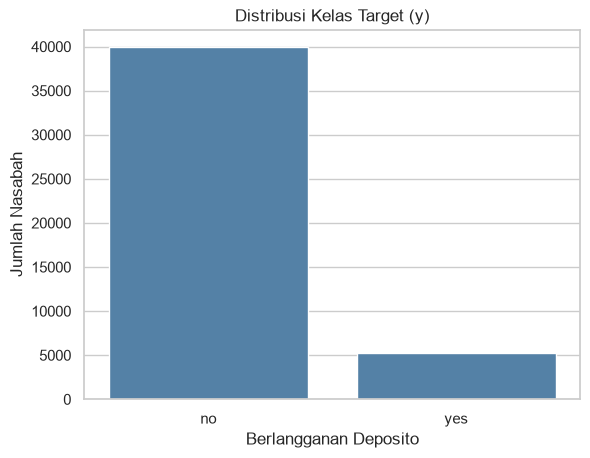

In [11]:
sns.countplot(x="y", data=df, color="steelblue")
plt.title("Distribusi Kelas Target (y)")
plt.xlabel("Berlangganan Deposito")
plt.ylabel("Jumlah Nasabah")
plt.show()

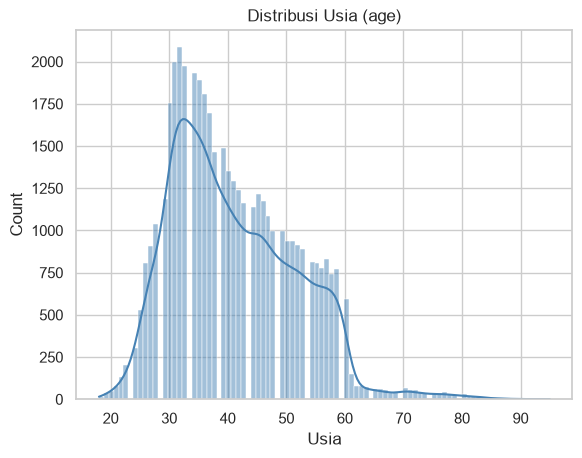

In [12]:
sns.histplot(df["age"], kde=True, color="steelblue")
plt.title("Distribusi Usia (age)")
plt.xlabel("Usia")
plt.show()

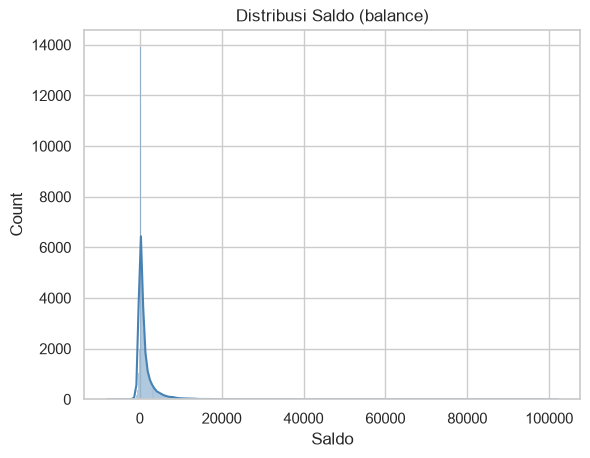

In [14]:
sns.histplot(df["balance"], kde=True, color="steelblue")
plt.title("Distribusi Saldo (balance)")
plt.xlabel("Saldo")
plt.show()

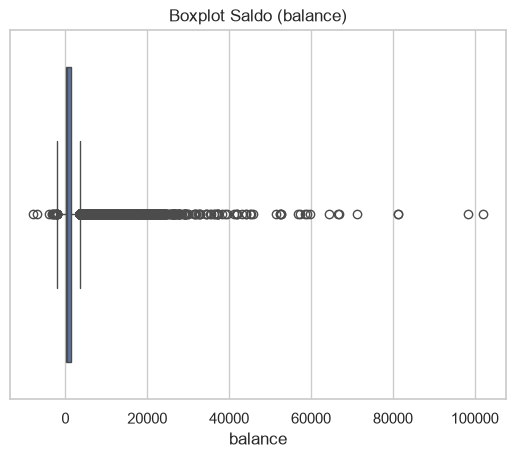

In [15]:
sns.boxplot(x=df["balance"])
plt.title("Boxplot Saldo (balance)")
plt.show()

In [16]:
Q1 = df["balance"].quantile(0.25)
Q3 = df["balance"].quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR
outliers = df[(df["balance"] < batas_bawah) | (df["balance"] > batas_atas)]

print("Q1 :", Q1)
print("Q3 :", Q3)
print("IQR:", IQR)
print("Batas bawah:", batas_bawah)
print("Batas atas :", batas_atas)
print("Jumlah outlier balance:", len(outliers))
print("Persentase outlier:", round(len(outliers) / len(df) * 100, 2), "%")

Q1 : 72.0
Q3 : 1428.0
IQR: 1356.0
Batas bawah: -1962.0
Batas atas : 3462.0
Jumlah outlier balance: 4729
Persentase outlier: 10.46 %


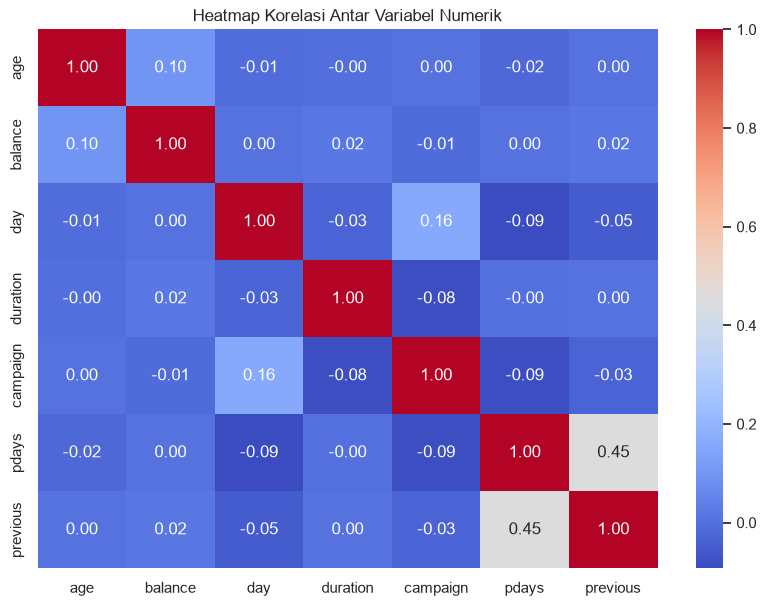

In [17]:
numeric_df = df.select_dtypes(include=["int64", "float64"])

plt.figure(figsize=(10,7))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Heatmap Korelasi Antar Variabel Numerik")
plt.show()

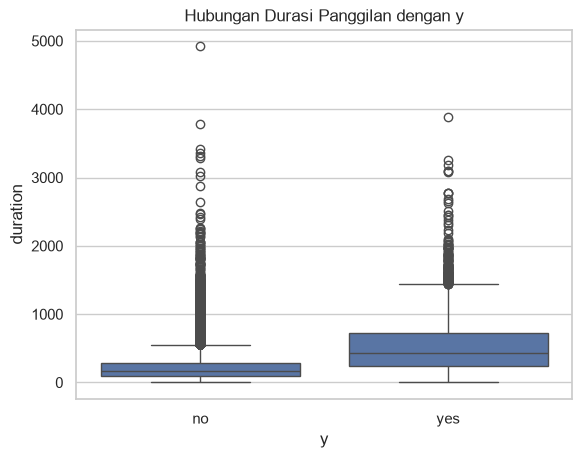

In [18]:
sns.boxplot(x="y", y="duration", data=df)
plt.title("Hubungan Durasi Panggilan dengan y")
plt.show()

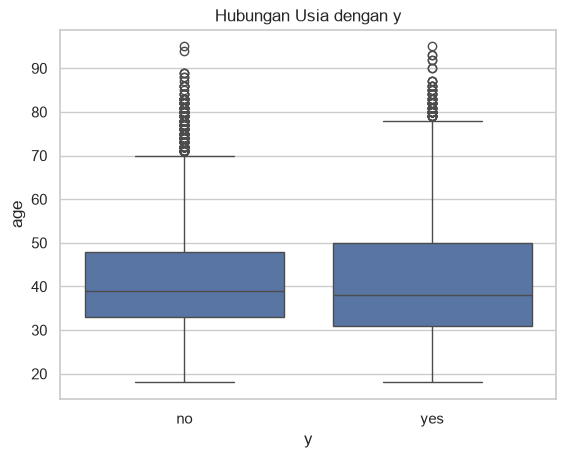

In [19]:
sns.boxplot(x="y", y="age", data=df)
plt.title("Hubungan Usia dengan y")
plt.show()


In [20]:
(pd.crosstab(df["poutcome"], df["y"], normalize="index") * 100).round(2)


y,no,yes
poutcome,,
failure,87.39,12.61
other,83.32,16.68
success,35.27,64.73
unknown,90.84,9.16


In [21]:
numeric_df.corr()["balance"].sort_values(ascending=False)


balance     1.000000
age         0.097783
duration    0.021560
previous    0.016674
day         0.004503
pdays       0.003435
campaign   -0.014578
Name: balance, dtype: float64

## 3. Preprocessing Data


In [22]:
print("Jumlah missing value:", df.isnull().sum().sum())
print("Jumlah data duplikat:", df.duplicated().sum())

#memeriksa nilai unknown pada kolom kategorikal
for kolom in ["job", "education", "contact", "poutcome"]:
    print(kolom, ":", (df[kolom] == "unknown").sum())

#memeriksa kode khusus pdays
print("Jumlah pdays bernilai -1:", (df["pdays"] == -1).sum())

Jumlah missing value: 0
Jumlah data duplikat: 0
job : 288
education : 1857
contact : 13020
poutcome : 36959
Jumlah pdays bernilai -1: 36954


## 4. Regresi Linear

### 4.1 Regresi Linear Sederhana

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [25]:
x = df[["age"]]
y = df["balance"]

In [26]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)
print("Data latih:", x_train.shape)
print("Data uji  :", x_test.shape)

Data latih: (36168, 1)
Data uji  : (9043, 1)


In [27]:
lm = LinearRegression()

In [28]:
lm.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[29.39]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['age']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,169.4
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [29]:
y_pred = lm.predict(x_test)

In [30]:
print("Coefficient:", lm.coef_)
print("Intercept  :", lm.intercept_)
print("MSE        :", mean_squared_error(y_test, y_pred))
print("RMSE       :", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score   :", r2_score(y_test, y_pred))

Coefficient: [29.39068049]
Intercept  : 169.37158131763272
MSE        : 8283698.401524639
RMSE       : 2878.1414839310173
R2 Score   : 0.0060708877690296426


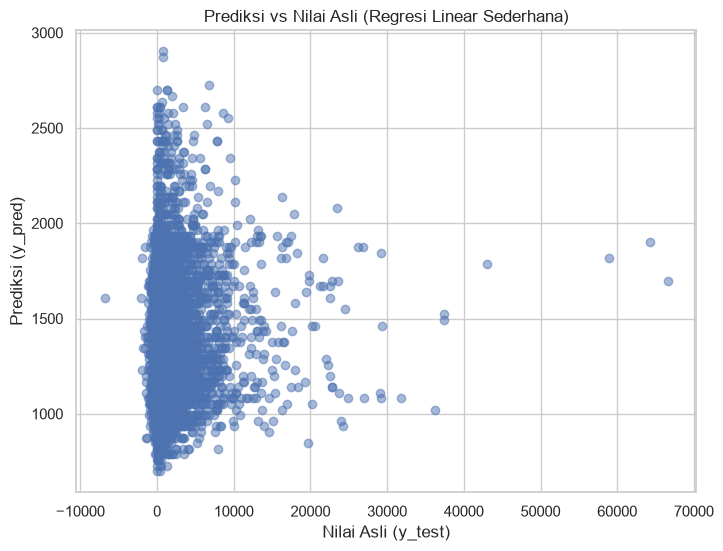

In [31]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Nilai Asli (y_test)")
plt.ylabel("Prediksi (y_pred)")
plt.title("Prediksi vs Nilai Asli (Regresi Linear Sederhana)")
plt.show()

### 4.2 Regresi Linear Berganda


In [32]:
#menyiapkan nilai x dan y
x = df.drop(columns=["balance", "y"])
x = pd.get_dummies(x, drop_first=True, dtype=int)
y = df["balance"]

print("Jumlah fitur setelah encoding:", x.shape[1])
x.head()


#memastikan seluruh fitur sudah berbentuk numerik dan tidak memiliki missing value
print("Missing value pada fitur:", x.isnull().sum().sum())
print("Jumlah fitur kategorikal tersisa:", len(x.select_dtypes(include=["object"]).columns))

Jumlah fitur setelah encoding: 41
Missing value pada fitur: 0
Jumlah fitur kategorikal tersisa: 0


In [33]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)
print("Data latih:", x_train.shape)
print("Data uji  :", x_test.shape)

Data latih: (36168, 41)
Data uji  : (9043, 41)


In [34]:
model = LinearRegression()

In [35]:
model.fit(x_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](41,)","[ 27.83, 5.66, 0.2 ,..., 130.23, 171.34,-155.29]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](41,)","['age','day','duration',...,'poutcome_other','poutcome_success', 'poutcome_unknown']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,43.37
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,41
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(41)


In [36]:
y_pred = model.predict(x_test)


In [37]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Coefficient:", model.coef_)
print("Intercept  :", model.intercept_)
print("MSE        :", mse)
print("RMSE       :", rmse)
print("R2 Score   :", r2)

Coefficient: [ 2.78303318e+01  5.65570007e+00  2.04460814e-01 -1.13765256e+00
 -8.83212277e-01  3.86682796e+00  1.50693869e+01  2.03851241e+02
 -6.13069991e+00  1.94289501e+02  1.84029941e+02  2.62659969e+02
 -2.10638311e+01  2.29750367e+02  6.53528684e+01  2.06534615e+02
  1.36950024e+02  3.08441201e+02  3.54988543e+02  1.11004712e+02
  5.02264912e+02  6.21958708e+01 -1.28036967e+03 -2.12674664e+02
 -5.67038750e+02  2.11130390e+02 -1.39850630e+02 -3.53747707e+02
  4.02352475e+02 -2.45980759e+02 -7.55462725e+02 -5.73247035e+02
  2.11073238e+02  2.08790912e+02 -2.27275472e+02  9.29167968e+02
  2.49014823e+02  1.18335727e+02  1.30226871e+02  1.71342665e+02
 -1.55287314e+02]
Intercept  : 43.37123224809875
MSE        : 8036521.379251603
RMSE       : 2834.875901913804
R2 Score   : 0.035728708032804035


In [38]:
hasil_reg = pd.DataFrame({
    "Nilai Aktual": y_test.iloc[:10].values,
    "Hasil Prediksi": y_pred[:10].round(2)
})
hasil_reg

,Nilai Aktual,Hasil Prediksi
0,1403,1195.86
1,-253,1420.54
2,-406,680.59
3,501,823.72
4,-406,-1246.66
5,-291,416.33
6,1803,760.88
7,431,525.01
8,879,3290.84
9,-90,1181.80


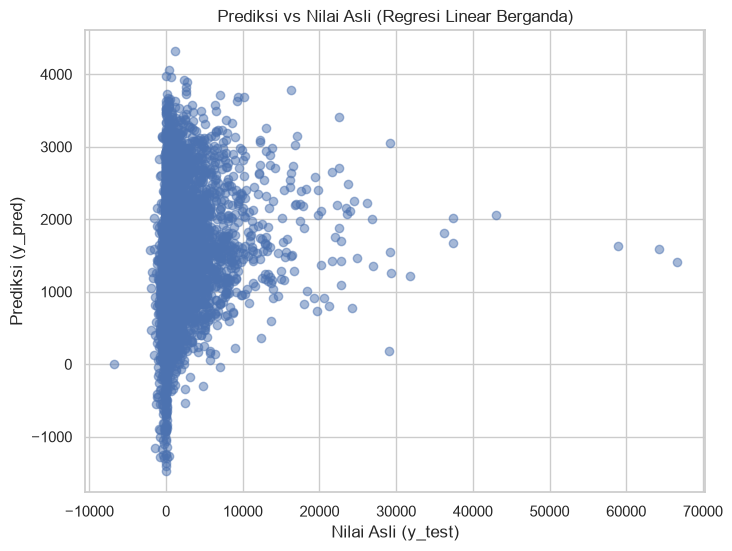

In [39]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Nilai Asli (y_test)")
plt.ylabel("Prediksi (y_pred)")
plt.title("Prediksi vs Nilai Asli (Regresi Linear Berganda)")
plt.show()

## 5. Decision Tree


In [40]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_enc = le.fit_transform(df["y"])
print(np.unique(y_enc))

for i, label in enumerate(le.classes_):
    print(f"{i} = {label}")

[0 1]
0 = no
1 = yes


In [41]:
#menyiapkan x dan y
x = df.drop(columns=["y"])
x = pd.get_dummies(x, dtype=int)
y = y_enc

print("Ukuran x:", x.shape)
x.head()

#memastikan seluruh fitur sudah berbentuk numerik dan tidak memiliki missing value
print("Missing value pada fitur:", x.isnull().sum().sum())
print("Jumlah fitur kategorikal tersisa:", len(x.select_dtypes(include=["object"]).columns))

Ukuran x: (45211, 51)
Missing value pada fitur: 0
Jumlah fitur kategorikal tersisa: 0


In [42]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=0, stratify=y
)
print("Data latih:", x_train.shape)
print("Data uji  :", x_test.shape)

Data latih: (36168, 51)
Data uji  : (9043, 51)


### 5.1 Model Decision Tree tanpa pembatasan (default)


In [43]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

classifier_default = DecisionTreeClassifier(random_state=0)
classifier_default.fit(x_train, y_train)

print("Kedalaman pohon:", classifier_default.get_depth())
print("Jumlah daun    :", classifier_default.get_n_leaves())
print("Akurasi data latih:", round(accuracy_score(y_train, classifier_default.predict(x_train)), 4))
print("Akurasi data uji  :", round(accuracy_score(y_test, classifier_default.predict(x_test)), 4))

Kedalaman pohon: 38
Jumlah daun    : 2930
Akurasi data latih: 1.0
Akurasi data uji  : 0.8728


### 5.2 Membandingkan nilai max_depth dengan entropy


In [45]:
x_train_dt, x_valid, y_train_dt, y_valid = train_test_split(
    x_train, y_train, test_size=0.2, random_state=0, stratify=y_train
)

hasil_depth = []
for d in [2, 3, 4, 5, 6, 8, 10]:
    model_dt = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=0)
    model_dt.fit(x_train_dt, y_train_dt)

    akurasi_latih = accuracy_score(y_train_dt, model_dt.predict(x_train_dt))
    akurasi_validasi = accuracy_score(y_valid, model_dt.predict(x_valid))

    hasil_depth.append((d, akurasi_validasi))
    print("max_depth =", d,
          "| akurasi latih:", round(akurasi_latih, 4),
          "| akurasi validasi:", round(akurasi_validasi, 4))

#memilih akurasi validasi tertinggi; jika seri, memilih pohon yang lebih sederhana
best_depth = sorted(hasil_depth, key=lambda item: (-item[1], item[0]))[0][0]
print("\nMax_depth terpilih berdasarkan data validasi:", best_depth)

max_depth = 2 | akurasi latih: 0.8876 | akurasi validasi: 0.8875
max_depth = 3 | akurasi latih: 0.9005 | akurasi validasi: 0.898
max_depth = 4 | akurasi latih: 0.9008 | akurasi validasi: 0.8974
max_depth = 5 | akurasi latih: 0.9042 | akurasi validasi: 0.8994
max_depth = 6 | akurasi latih: 0.907 | akurasi validasi: 0.9013
max_depth = 8 | akurasi latih: 0.9136 | akurasi validasi: 0.9007
max_depth = 10 | akurasi latih: 0.9232 | akurasi validasi: 0.9012

Max_depth terpilih berdasarkan data validasi: 6


### 5.3 Melatih model akhir dan menampilkan pohon


In [46]:
classifier = DecisionTreeClassifier(
    criterion="entropy", max_depth=best_depth, random_state=0
)
classifier.fit(x_train, y_train)

print("Kedalaman pohon akhir:", classifier.get_depth())
print("Jumlah daun akhir    :", classifier.get_n_leaves())

Kedalaman pohon akhir: 6
Jumlah daun akhir    : 62


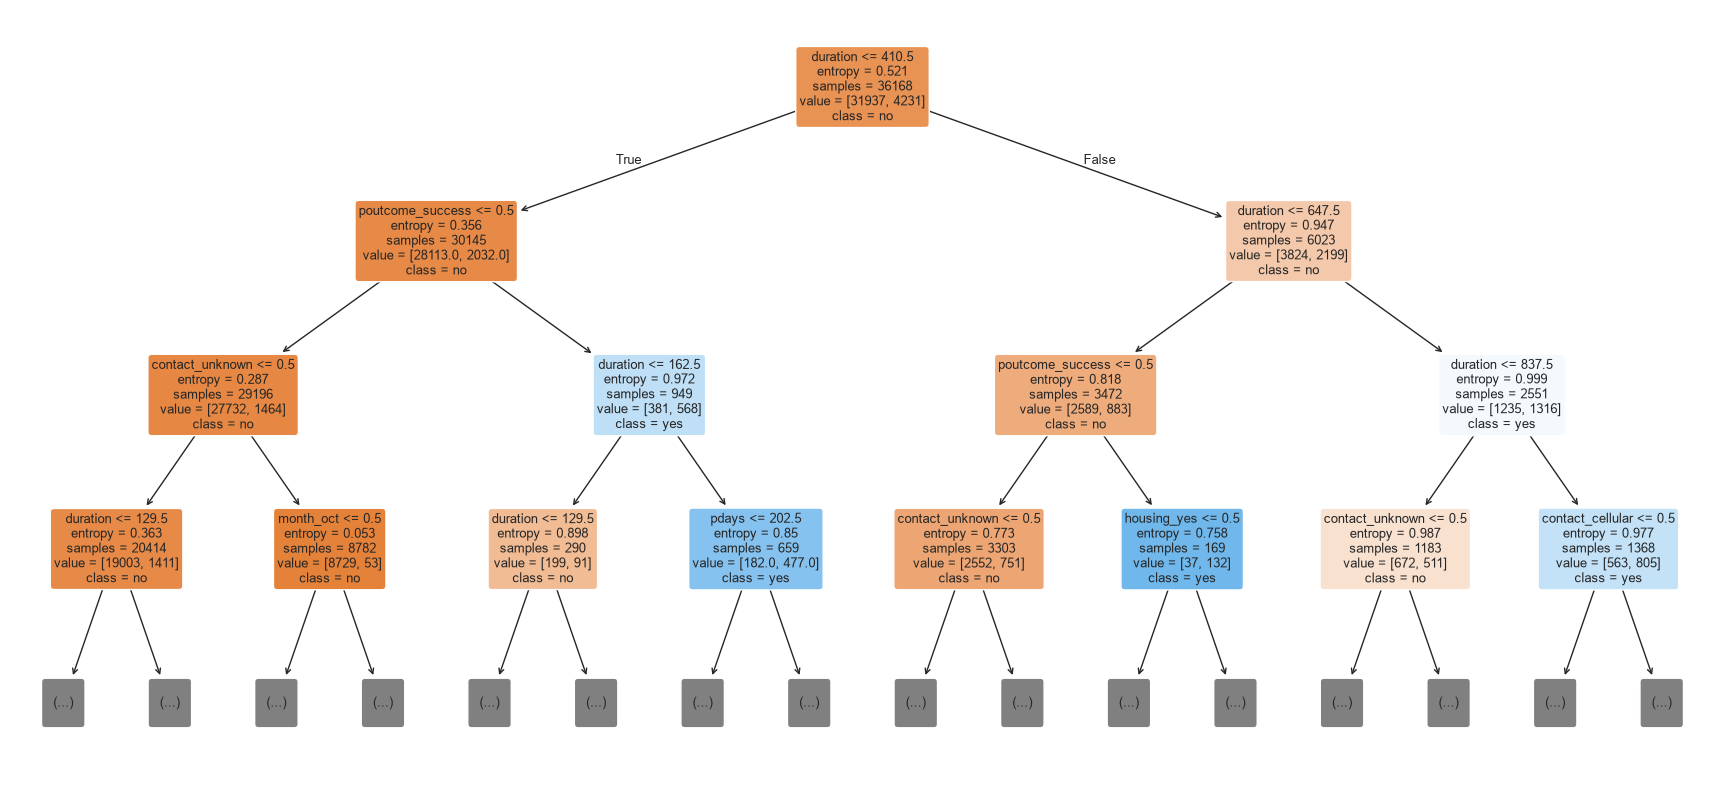

In [47]:
from sklearn import tree

plt.subplots(figsize=(22, 10))
tree.plot_tree(classifier, max_depth=3, feature_names=x.columns, class_names=le.classes_,
               filled=True, rounded=True, fontsize=9)
plt.show()

### 5.4 Prediksi dan Evaluasi

In [49]:
y_pred = classifier.predict(x_test)
akurasi = accuracy_score(y_test, y_pred)
print("Akurasi data uji:", round(akurasi, 4))

Akurasi data uji: 0.9009


In [50]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[7790  195]
 [ 701  357]]


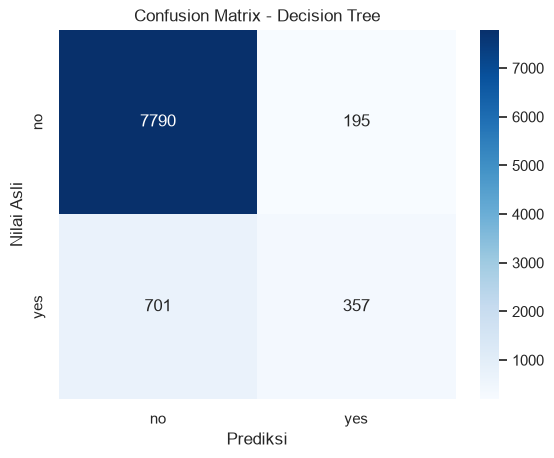

In [51]:
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Prediksi")
plt.ylabel("Nilai Asli")
plt.title("Confusion Matrix - Decision Tree")
plt.show()

## 6. Ringkasan Hasil

In [52]:
print("REGRESI LINEAR BERGANDA (target: balance)")
print("MSE      :", round(mse, 4))
print("RMSE     :", round(rmse, 4))
print("R2 Score :", round(r2, 4))
print()
print("DECISION TREE (target: y, entropy, max_depth =", best_depth, ")")
print("Akurasi  :", round(akurasi, 4))

REGRESI LINEAR BERGANDA (target: balance)
MSE      : 8036521.3793
RMSE     : 2834.8759
R2 Score : 0.0357

DECISION TREE (target: y, entropy, max_depth = 6 )
Akurasi  : 0.9009
